In [1]:
import sqlite3
import pandas as pd

# Load the SpaceX launch table and put it into an in-memory SQLite database
url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/labs/module_2/data/Spacex.csv"
df = pd.read_csv(url)
df = df.dropna(subset=['Date'])
con = sqlite3.connect(":memory:")
df.to_sql("SPACEXTABLE", con, index=False)

def q(title, sql):
    print("\n" + title)
    print(pd.read_sql(sql, con).to_string(index=False))

q("Task 1: unique launch sites",
  "SELECT DISTINCT Launch_Site FROM SPACEXTABLE")

q("Task 2: five records where the launch site starts with 'CCA'",
  "SELECT * FROM SPACEXTABLE WHERE Launch_Site LIKE 'CCA%' LIMIT 5")

q("Task 3: total payload mass carried for NASA (CRS)",
  "SELECT SUM(PAYLOAD_MASS__KG_) AS total_payload_kg FROM SPACEXTABLE WHERE Customer = 'NASA (CRS)'")

q("Task 4: average payload mass for booster F9 v1.1",
  "SELECT AVG(PAYLOAD_MASS__KG_) AS avg_payload_kg FROM SPACEXTABLE WHERE Booster_Version = 'F9 v1.1'")

q("Task 5: date of the first successful ground pad landing",
  "SELECT MIN(Date) AS first_success FROM SPACEXTABLE WHERE Landing_Outcome = 'Success (ground pad)'")

q("Task 6: boosters with drone ship success and payload between 4000 and 6000 kg",
  "SELECT DISTINCT Booster_Version FROM SPACEXTABLE WHERE Landing_Outcome = 'Success (drone ship)' AND PAYLOAD_MASS__KG_ > 4000 AND PAYLOAD_MASS__KG_ < 6000")

q("Task 7: total number of successful and failed mission outcomes",
  "SELECT Mission_Outcome, COUNT(*) AS total FROM SPACEXTABLE GROUP BY Mission_Outcome")

q("Task 8: boosters that carried the maximum payload",
  "SELECT DISTINCT Booster_Version FROM SPACEXTABLE WHERE PAYLOAD_MASS__KG_ = (SELECT MAX(PAYLOAD_MASS__KG_) FROM SPACEXTABLE)")

q("Task 9: 2015 drone ship landing failures",
  "SELECT substr(Date,6,2) AS month, Landing_Outcome, Booster_Version, Launch_Site FROM SPACEXTABLE WHERE Landing_Outcome = 'Failure (drone ship)' AND substr(Date,0,5) = '2015'")

q("Task 10: rank landing outcomes between 2010-06-04 and 2017-03-20",
  "SELECT Landing_Outcome, COUNT(*) AS cnt FROM SPACEXTABLE WHERE Date BETWEEN '2010-06-04' AND '2017-03-20' GROUP BY Landing_Outcome ORDER BY cnt DESC")


Task 1: unique launch sites
 Launch_Site
 CCAFS LC-40
 VAFB SLC-4E
  KSC LC-39A
CCAFS SLC-40

Task 2: five records where the launch site starts with 'CCA'
      Date Time (UTC) Booster_Version Launch_Site                                                       Payload  PAYLOAD_MASS__KG_     Orbit        Customer Mission_Outcome     Landing_Outcome
2010-06-04   18:45:00  F9 v1.0  B0003 CCAFS LC-40                          Dragon Spacecraft Qualification Unit                  0       LEO          SpaceX         Success Failure (parachute)
2010-12-08   15:43:00  F9 v1.0  B0004 CCAFS LC-40 Dragon demo flight C1, two CubeSats, barrel of Brouere cheese                  0 LEO (ISS) NASA (COTS) NRO         Success Failure (parachute)
2012-05-22    7:44:00  F9 v1.0  B0005 CCAFS LC-40                                         Dragon demo flight C2                525 LEO (ISS)     NASA (COTS)         Success          No attempt
2012-10-08    0:35:00  F9 v1.0  B0006 CCAFS LC-40                       

In [2]:
import sqlite3
import pandas as pd

url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/labs/module_2/data/Spacex.csv"
df = pd.read_csv(url).dropna(subset=['Date'])
con = sqlite3.connect(":memory:")
df.to_sql("SPACEXTABLE", con, index=False)

def q(sql):
    return pd.read_sql(sql, con)

In [3]:
q("SELECT DISTINCT Launch_Site FROM SPACEXTABLE")

,Launch_Site
0,CCAFS LC-40
1,VAFB SLC-4E
2,KSC LC-39A
3,CCAFS SLC-40


In [4]:
q("SELECT * FROM SPACEXTABLE WHERE Launch_Site LIKE 'CCA%' LIMIT 5")

,Date,Time (UTC),Booster_Version,Launch_Site,Payload,PAYLOAD_MASS__KG_,Orbit,Customer,Mission_Outcome,Landing_Outcome
0,2010-06-04,18:45:00,F9 v1.0 B0003,CCAFS LC-40,Dragon Spacecraft Qualification Unit,0,LEO,SpaceX,Success,Failure (parachute)
1,2010-12-08,15:43:00,F9 v1.0 B0004,CCAFS LC-40,"Dragon demo flight C1, two CubeSats, barrel of...",0,LEO (ISS),NASA (COTS) NRO,Success,Failure (parachute)
2,2012-05-22,7:44:00,F9 v1.0 B0005,CCAFS LC-40,Dragon demo flight C2,525,LEO (ISS),NASA (COTS),Success,No attempt
3,2012-10-08,0:35:00,F9 v1.0 B0006,CCAFS LC-40,SpaceX CRS-1,500,LEO (ISS),NASA (CRS),Success,No attempt
4,2013-03-01,15:10:00,F9 v1.0 B0007,CCAFS LC-40,SpaceX CRS-2,677,LEO (ISS),NASA (CRS),Success,No attempt


In [5]:
q("SELECT SUM(PAYLOAD_MASS__KG_) AS total_payload_kg FROM SPACEXTABLE WHERE Customer = 'NASA (CRS)'")

,total_payload_kg
0,45596


In [6]:
q("SELECT AVG(PAYLOAD_MASS__KG_) AS avg_payload_kg FROM SPACEXTABLE WHERE Booster_Version = 'F9 v1.1'")

,avg_payload_kg
0,2928.4


In [7]:
q("SELECT MIN(Date) AS first_success FROM SPACEXTABLE WHERE Landing_Outcome = 'Success (ground pad)'")

,first_success
0,2015-12-22


In [8]:
q("SELECT DISTINCT Booster_Version FROM SPACEXTABLE WHERE Landing_Outcome = 'Success (drone ship)' AND PAYLOAD_MASS__KG_ > 4000 AND PAYLOAD_MASS__KG_ < 6000")

,Booster_Version
0,F9 FT B1022
1,F9 FT B1026
2,F9 FT B1021.2
3,F9 FT B1031.2


In [9]:
q("SELECT Mission_Outcome, COUNT(*) AS total FROM SPACEXTABLE GROUP BY Mission_Outcome")

,Mission_Outcome,total
0,Failure (in flight),1
1,Success,98
2,Success,1
3,Success (payload status unclear),1


In [10]:
q("SELECT DISTINCT Booster_Version FROM SPACEXTABLE WHERE PAYLOAD_MASS__KG_ = (SELECT MAX(PAYLOAD_MASS__KG_) FROM SPACEXTABLE)")

,Booster_Version
0,F9 B5 B1048.4
1,F9 B5 B1049.4
2,F9 B5 B1051.3
3,F9 B5 B1056.4
4,F9 B5 B1048.5
5,F9 B5 B1051.4
6,F9 B5 B1049.5
7,F9 B5 B1060.2
8,F9 B5 B1058.3
9,F9 B5 B1051.6


In [11]:
q("SELECT substr(Date,6,2) AS month, Landing_Outcome, Booster_Version, Launch_Site FROM SPACEXTABLE WHERE Landing_Outcome = 'Failure (drone ship)' AND substr(Date,0,5) = '2015'")

,month,Landing_Outcome,Booster_Version,Launch_Site
0,01,Failure (drone ship),F9 v1.1 B1012,CCAFS LC-40
1,04,Failure (drone ship),F9 v1.1 B1015,CCAFS LC-40


In [12]:
q("SELECT Landing_Outcome, COUNT(*) AS cnt FROM SPACEXTABLE WHERE Date BETWEEN '2010-06-04' AND '2017-03-20' GROUP BY Landing_Outcome ORDER BY cnt DESC")

,Landing_Outcome,cnt
0,No attempt,10
1,Success (drone ship),5
2,Failure (drone ship),5
3,Success (ground pad),3
4,Controlled (ocean),3
5,Uncontrolled (ocean),2
6,Failure (parachute),2
7,Precluded (drone ship),1


Test set size: 18


c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:


Logistic Regression
  best params: {'C': 1, 'penalty': 'l2', 'solver': 'lbfgs'}
  validation accuracy: 0.8214
  test accuracy: 0.8333


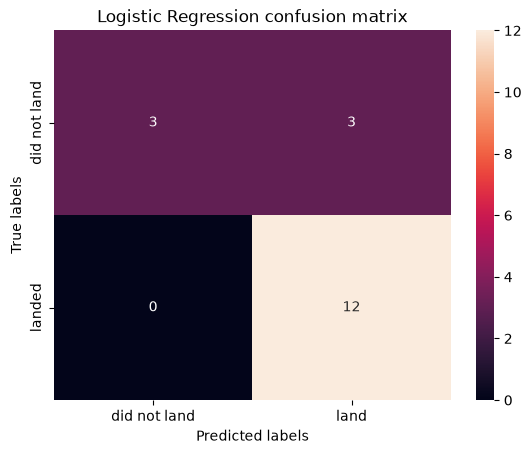


SVM
  best params: {'C': np.float64(1.0), 'gamma': np.float64(0.03162277660168379), 'kernel': 'sigmoid'}
  validation accuracy: 0.8482
  test accuracy: 0.8333


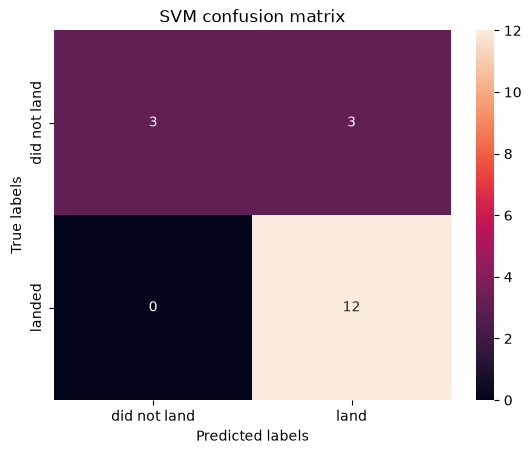


Decision Tree
  best params: {'criterion': 'entropy', 'max_depth': 12, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'splitter': 'random'}
  validation accuracy: 0.8607
  test accuracy: 0.7778


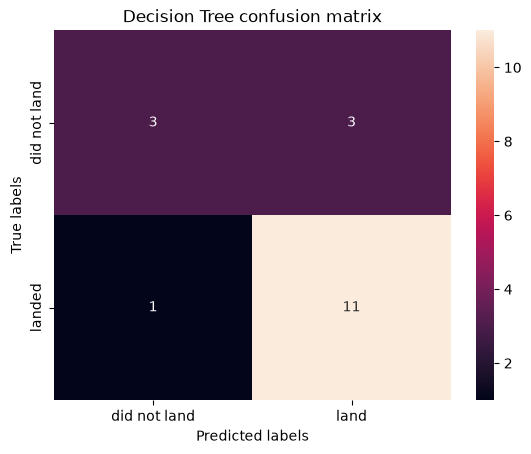


KNN
  best params: {'algorithm': 'auto', 'n_neighbors': 6, 'p': 1}
  validation accuracy: 0.8339
  test accuracy: 0.8333


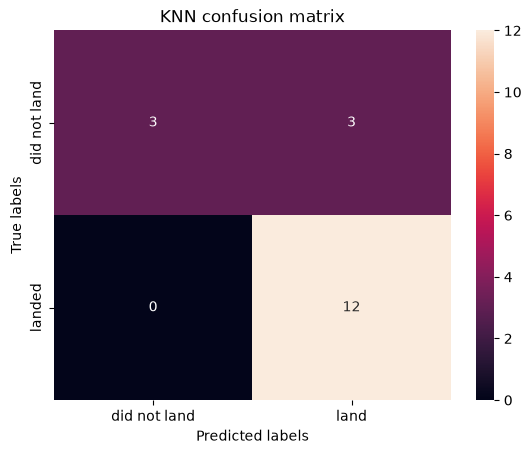


Test accuracy summary:
Logistic Regression    0.833333
SVM                    0.833333
KNN                    0.833333
Decision Tree          0.777778
dtype: float64


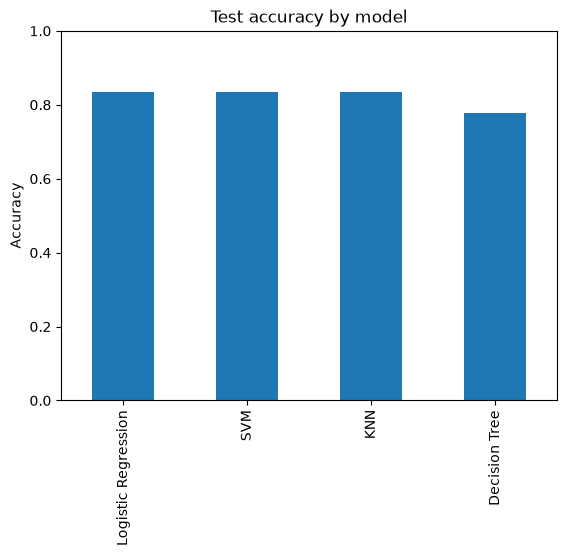

Best model: Logistic Regression


In [13]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn import preprocessing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix

data = pd.read_csv(r"C:\Users\DELL\Downloads\dataset_part_2.csv")
X = pd.read_csv(r"C:\Users\DELL\Downloads\dataset_part_3.csv")
Y = data['Class'].to_numpy()

# Task 1-2: standardize and split
X = preprocessing.StandardScaler().fit_transform(X)
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=2)
print("Test set size:", Y_test.shape[0])

def plot_cm(y, y_pred, title):
    cm = confusion_matrix(y, y_pred)
    ax = plt.subplot()
    sns.heatmap(cm, annot=True, ax=ax)
    ax.set_xlabel('Predicted labels'); ax.set_ylabel('True labels')
    ax.set_title(title); ax.xaxis.set_ticklabels(['did not land', 'land'])
    ax.yaxis.set_ticklabels(['did not land', 'landed'])
    plt.show()

models = {
    'Logistic Regression': (LogisticRegression(), {'C':[0.01,0.1,1], 'penalty':['l2'], 'solver':['lbfgs']}),
    'SVM': (SVC(), {'kernel':('linear','rbf','poly','sigmoid'), 'C':np.logspace(-3,3,5), 'gamma':np.logspace(-3,3,5)}),
    'Decision Tree': (DecisionTreeClassifier(), {'criterion':['gini','entropy'], 'splitter':['best','random'],
        'max_depth':[2*n for n in range(1,10)], 'max_features':['sqrt'], 'min_samples_leaf':[1,2,4], 'min_samples_split':[2,5,10]}),
    'KNN': (KNeighborsClassifier(), {'n_neighbors':list(range(1,11)), 'algorithm':['auto','ball_tree','kd_tree','brute'], 'p':[1,2]}),
}

results = {}
for name, (model, params) in models.items():
    gs = GridSearchCV(model, params, cv=10)
    gs.fit(X_train, Y_train)
    test_acc = gs.score(X_test, Y_test)
    results[name] = test_acc
    print(f"\n{name}\n  best params: {gs.best_params_}\n  validation accuracy: {gs.best_score_:.4f}\n  test accuracy: {test_acc:.4f}")
    plot_cm(Y_test, gs.predict(X_test), f"{name} confusion matrix")

print("\nTest accuracy summary:")
summary = pd.Series(results).sort_values(ascending=False)
print(summary)
summary.plot(kind='bar', ylim=(0,1), title='Test accuracy by model')
plt.ylabel('Accuracy'); plt.show()
print("Best model:", summary.index[0])